# 05 · Results and classification

Every run writes its result to disk once, as data, so it can be analysed and plotted
later without running anything again. This notebook reads back the run notebook 04
made and goes through it:

1. **The run folder**: what is saved where
2. **Selected models**: which hyperparameters each metric chose
3. **Source recovery**: how well each model recovered the sources (synthetic data)
4. **Classification**: telling the trials apart from the recovered components
5. **Inputs and all runs**: the preprocessed data and the index of every run

Run notebook 04 first, or `python main.py` with the same two configs.

In [1]:
SUBJECT_CONFIG = "configs/subjects/synthetic/sub01/sub01_snr_fnirs-5_eeg5.yaml"
EXPERIMENT_CONFIG = "configs/experiments/tutorial.yaml"

# For your own data, point SUBJECT_CONFIG at its subject config. If its files are in a
# format the pipeline does not read yet, add a loader for it first (notebook 06).

In [2]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.classification import classification_report
from src.config import load_experiment, load_subject
from src.log import setup_logging
from src.results import RESULTS_DIR, load_inputs, load_run
from src.visualization import (plot_classification, plot_inputs, plot_isi,
                               plot_pattern_recovery, plot_selection_landscape,
                               plot_source_recovery, selected_params)

logger = setup_logging()
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

subject = load_subject(PROJECT_ROOT / SUBJECT_CONFIG)
cfg = load_experiment(PROJECT_ROOT / EXPERIMENT_CONFIG)

## 1. The run folder

A run is saved to `results/runs/<experiment>/<dataset>/<started>/`. The latest run of
this experiment on this dataset:

In [3]:
runs_dir = RESULTS_DIR / "runs" / cfg.name / subject.name
run_dir = sorted(p for p in runs_dir.iterdir() if (p / "results" / "run.json").exists())[-1]
print(f"Run folder: {run_dir.relative_to(PROJECT_ROOT)}")
for kind in ("results", "figures"):
    files = sorted(p.relative_to(run_dir / kind) for p in (run_dir / kind).rglob("*") if p.is_file())
    print(f"\n{kind}/: {len(files)} files")
    print("  " + "\n  ".join(str(f) for f in files[:14]) + ("\n  ..." if len(files) > 14 else ""))

Run folder: results/runs/tutorial/sub01_snr_fnirs-5_eeg5/2026-11-09T08-39-24

results/: 40 files
  alignment.csv
  bad_channels.json
  classification.csv
  combinations.csv
  experiment.yaml
  geometry.nc
  landscape.csv
  models/non_nested_sitting_post_rest_1_CCA_0.nc
  models/non_nested_sitting_post_rest_1_ElasticNetCCA_2.nc
  models/non_nested_sitting_post_rest_1_ElasticNetTCCA_3.nc
  models/non_nested_sitting_post_rest_1_ElasticNetTCCA_4.nc
  models/non_nested_sitting_post_rest_1_SparseCCA_1.nc
  recovery/non_nested_sitting_post_rest_1_CCA_0.nc
  recovery/non_nested_sitting_post_rest_1_CCA_0_fold_sitting_post_rest_2.nc
  ...

figures/: 106 files
  bad_channels.png
  canonical_correlation_avg/CCA/assignment.png
  canonical_correlation_avg/CCA/fold_sitting_post_rest_2.png
  canonical_correlation_avg/CCA/fold_sitting_post_rest_2_patterns.png
  canonical_correlation_avg/CCA/fold_sitting_pre_rest_1.png
  canonical_correlation_avg/CCA/fold_sitting_pre_rest_1_patterns.png
  canonical_corr

- `results/` holds the data: both configs as they were used, the bad channels, every
  score (`scores.csv`), every grid point (`landscape.csv`, `combinations.csv`), the
  classification (`classification.csv`), the recovered components (`recovery/`) and
  every selected model with its full fitted state (`models/`)
- `figures/` holds the standard figures, drawn from that data

`load_run` reads it all back into the same `RunResult` the run returned. The models
are ready to apply to new data.

In [4]:
result = load_run(run_dir)
u = result.unmixing
print(f"Experiment {result.cfg.name!r} on {result.subject.name}, {result.started} to {result.finished}")
print(f"Test group {u.test_group}: {len(u.selections)} selected models, "
      f"{len(u.landscape)} grid points scored")

Experiment 'tutorial' on sub01_snr_fnirs-5_eeg5, 2026-11-09T08:39:24 to 2026-11-09T08:40:18
Test group sitting_post_rest_1: 8 selected models, 68 grid points scored


## 2. Selected models

For each method and metric, the hyperparameters selected by cross-validation on the
dev groups:

In [5]:
display(selected_params(result))

,joint_avg,canonical_correlation_avg
CCA,(none),(none)
SparseCCA,"l1_reg [0.25, 0.1] (edge: EEG, fNIRS)","l1_reg [0.25, 0.1] (edge: EEG, fNIRS)"
ElasticNetCCA,"l1_reg [0.2, 0.2] (edge: EEG, fNIRS) · l2_reg ...","l1_reg [0.2, 0.2] (edge: EEG, fNIRS) · l2_reg ..."
ElasticNetTCCA,"l1_reg [0.2, 0.2] · l2_reg [1, 1.5] (edge: fNI...","l1_reg [0.2, 0.2] · l2_reg [1, 1.2] (edge: fNI..."


How the validation score changes over a method's grid; the selected point is
highlighted.

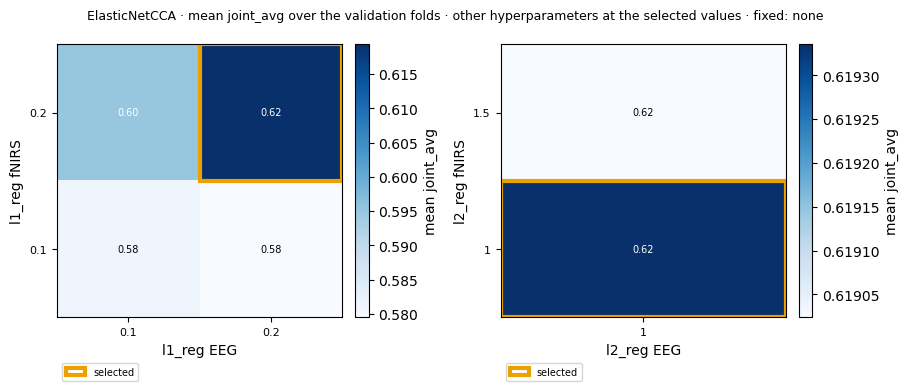

In [6]:
metric = result.cfg.unmixing.metrics[0]
fig = plot_selection_landscape(result, "ElasticNetCCA", metric)
plt.show()

## 3. Source recovery

The test scores of every selected model, one row per model and hand. `canonical_r` is
how strongly the pair's EEG and fNIRS components agree; with ground truth, `r_eeg`
and `r_fnirs` are how well each component matches its source (|r|, 1 is perfect),
and the ISI how cleanly the sources are separated (0 is perfect).

In [7]:
rows = []
for s in u.selections:
    for h, pair in s.scores.labels.pairs.items():
        rows.append({"method": s.method, "metric": s.metric, "hand": h, "pair": pair,
                     "canonical_r": s.scores.canonical_r[h],
                     "r_eeg": s.scores.r_eeg.get(h), "r_fnirs": s.scores.r_fnirs.get(h),
                     "isi_eeg": s.scores.isi_eeg, "isi_fnirs": s.scores.isi_fnirs})
display(pd.DataFrame(rows).round(2))

,method,metric,hand,pair,canonical_r,r_eeg,r_fnirs,isi_eeg,isi_fnirs
0,CCA,joint_avg,right_hand,1,0.16,0.41,0.41,0.12,0.05
1,CCA,joint_avg,left_hand,6,0.14,0.36,0.44,0.12,0.05
2,CCA,canonical_correlation_avg,right_hand,1,0.16,0.41,0.41,0.12,0.05
3,CCA,canonical_correlation_avg,left_hand,6,0.14,0.36,0.44,0.12,0.05
4,SparseCCA,joint_avg,right_hand,5,0.20,0.59,0.58,0.04,0.20
5,SparseCCA,joint_avg,left_hand,1,0.16,0.45,0.56,0.04,0.20
6,SparseCCA,canonical_correlation_avg,right_hand,5,0.20,0.59,0.58,0.04,0.20
7,SparseCCA,canonical_correlation_avg,left_hand,1,0.16,0.45,0.56,0.04,0.20
8,ElasticNetCCA,joint_avg,right_hand,0,0.27,0.51,0.81,0.04,0.05
9,ElasticNetCCA,joint_avg,left_hand,3,0.20,0.42,0.77,0.04,0.05


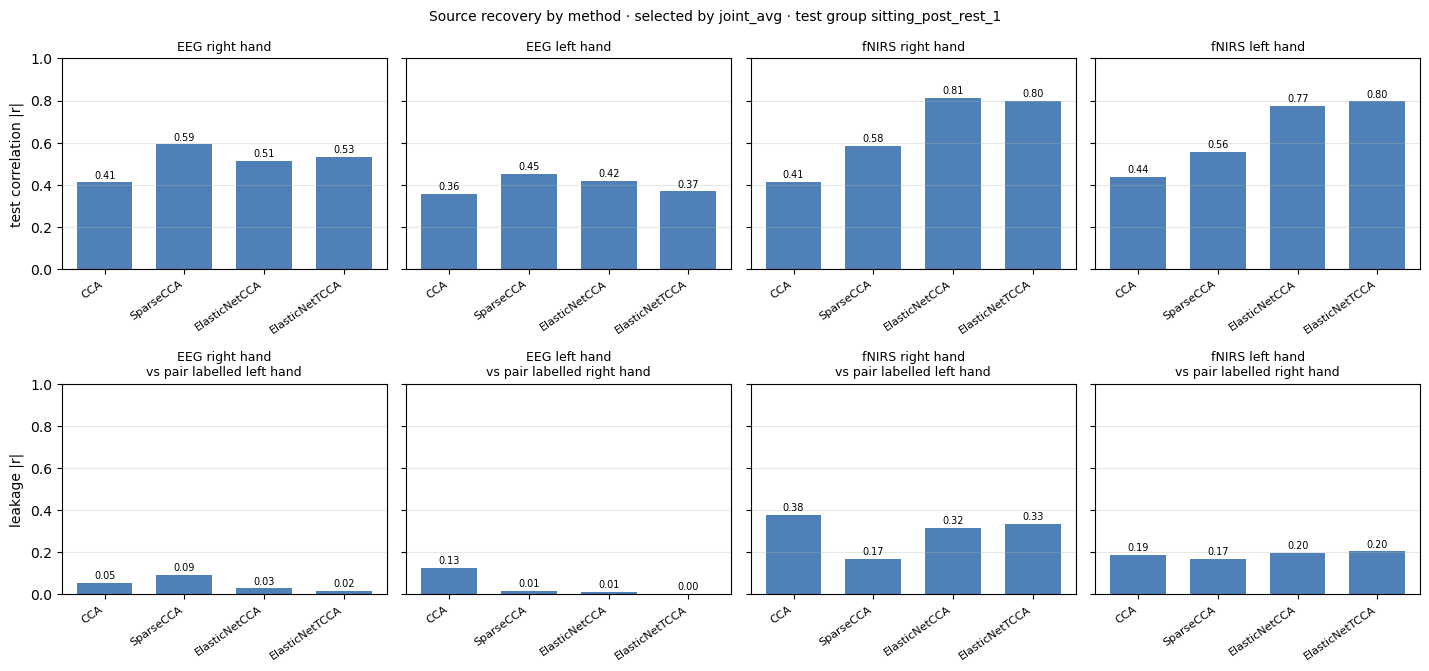

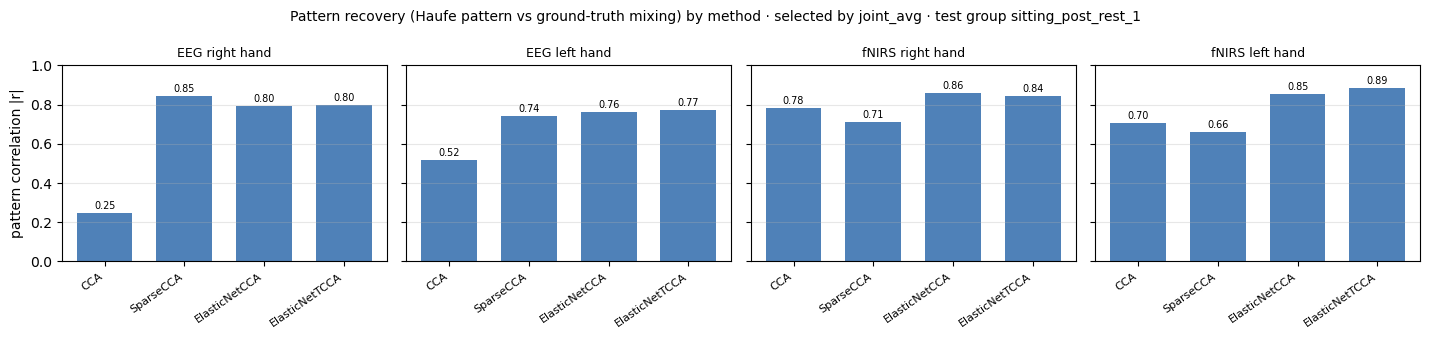

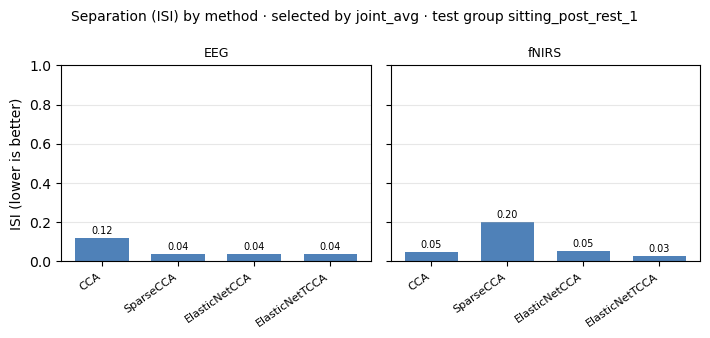

In [8]:
has_truth = bool(u.selections[0].scores.best_pairs)
if not has_truth:
    print("No ground truth: the recovery figures are skipped.")
else:
    for plot in (plot_source_recovery, plot_pattern_recovery, plot_isi):
        fig = plot(result, metric)
        plt.show()

## 4. Classification

With a `classification` section in the experiment, every selected model is used to
classify the test group's trials: each trial is cut from the model's components, a
few interval means after the trial onset become its features, and a regularised LDA
(rLDA) trained on the dev groups' trials predicts its class. This is done for the EEG
components, the fNIRS components and both together.

In [9]:
by_model = {}
for score in result.classification.scores:
    by_model.setdefault((score.method, score.metric), []).append(score)
for scores in by_model.values():
    print(classification_report(scores))

CCA by joint_avg: classification of test group sitting_post_rest_1, 116 training and 29 test trials (dropped 0 and 0)
    eeg_fnirs  accuracy 0.97  recall left 0.93  right 1.00
    eeg        accuracy 1.00  recall left 1.00  right 1.00
    fnirs      accuracy 0.90  recall left 0.93  right 0.87
CCA by canonical_correlation_avg: classification of test group sitting_post_rest_1, 116 training and 29 test trials (dropped 0 and 0)
    eeg_fnirs  accuracy 0.97  recall left 0.93  right 1.00
    eeg        accuracy 1.00  recall left 1.00  right 1.00
    fnirs      accuracy 0.90  recall left 0.93  right 0.87
SparseCCA by joint_avg: classification of test group sitting_post_rest_1, 116 training and 29 test trials (dropped 0 and 0)
    eeg_fnirs  accuracy 0.93  recall left 0.86  right 1.00
    eeg        accuracy 1.00  recall left 1.00  right 1.00
    fnirs      accuracy 0.83  recall left 0.86  right 0.80
SparseCCA by canonical_correlation_avg: classification of test group sitting_post_rest_1, 116

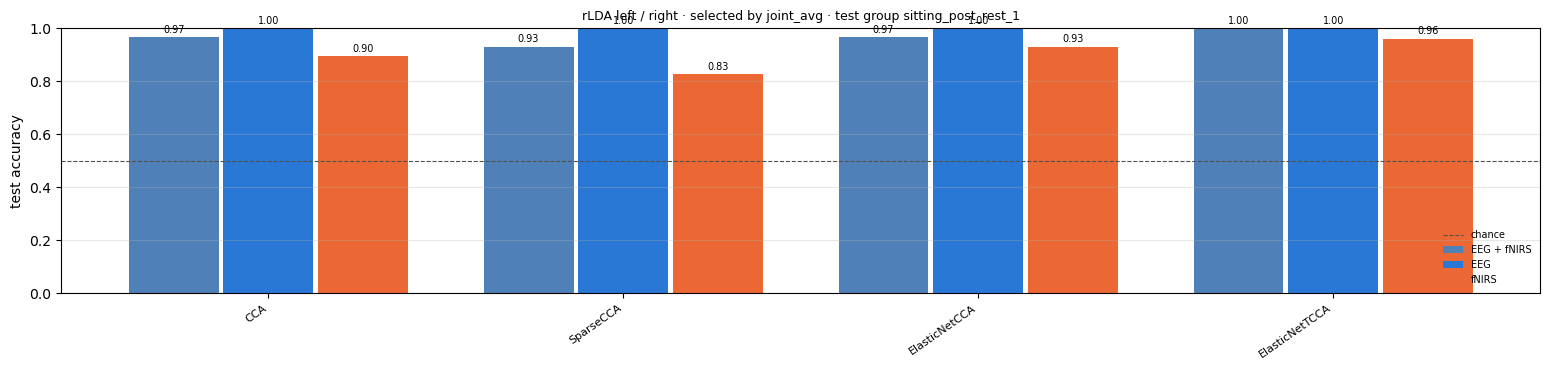

In [10]:
fig = plot_classification(result, metric)
plt.show()

The same numbers as a table, from `results/classification.csv`:

In [11]:
table = pd.read_csv(run_dir / "results" / "classification.csv")
display(table.pivot_table(index=["method", "metric"], columns="feature_set",
                          values="accuracy").round(2))

feature_set                               eeg  eeg_fnirs  fnirs
method         metric                                          
CCA            canonical_correlation_avg  1.0       0.97   0.90
               joint_avg                  1.0       0.97   0.90
ElasticNetCCA  canonical_correlation_avg  1.0       0.97   0.93
               joint_avg                  1.0       0.97   0.93
ElasticNetTCCA canonical_correlation_avg  1.0       0.96   0.96
               joint_avg                  1.0       1.00   0.96
SparseCCA      canonical_correlation_avg  1.0       0.93   0.83
               joint_avg                  1.0       0.93   0.83

## 5. Inputs and all runs

With `save_inputs: true` (the default) the preprocessed runs are saved too, so the
model inputs can be looked at later:

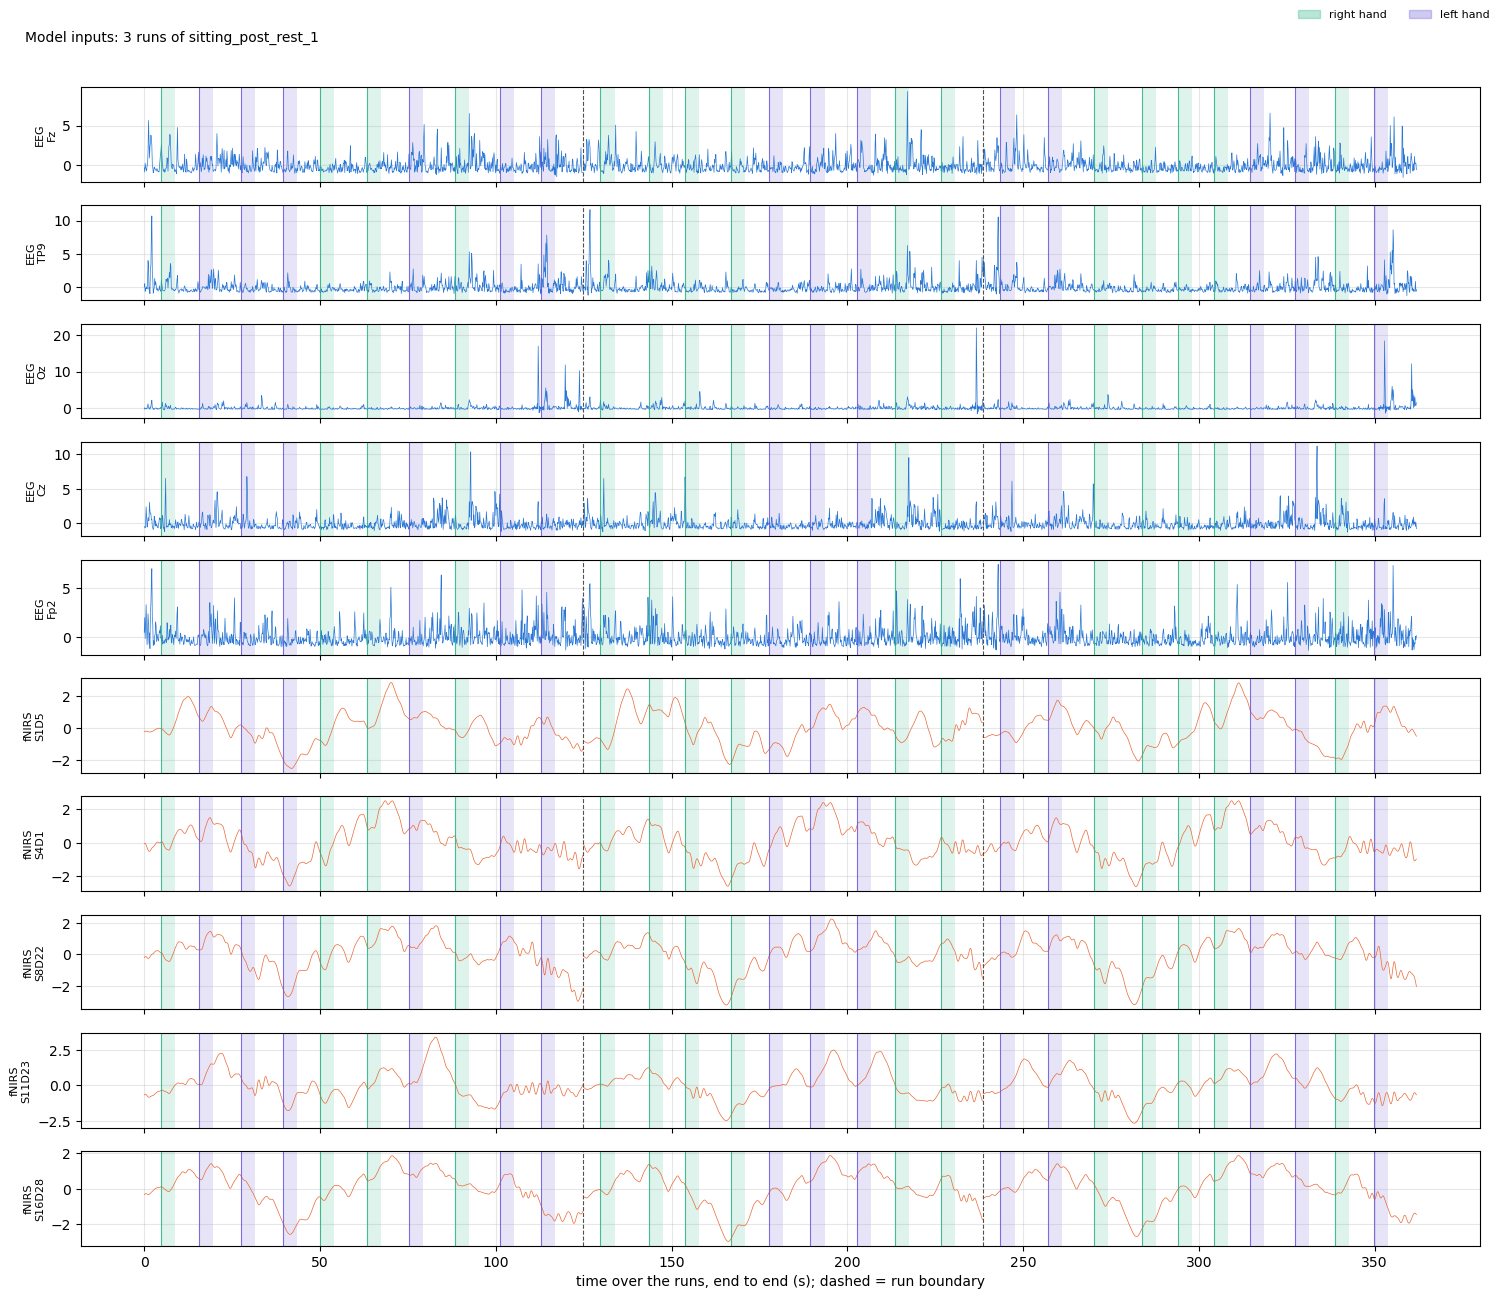

In [12]:
inputs = load_inputs(run_dir)
fig = plot_inputs(inputs, groups=[result.unmixing.test_group])
plt.show()

Every finished run adds a line to `results/runs/index.csv`, with its configs, the git
commit it ran on and its folder, so runs can be compared across subjects and
experiments:

In [13]:
index = pd.read_csv(RESULTS_DIR / "runs" / "index.csv")
display(index[["started", "experiment", "dataset", "test_group", "methods", "folder"]].tail())

,started,experiment,dataset,test_group,methods,folder
0,2026-10-30T18:05:17,tutorial,sub01_snr_fnirs-5_eeg5,sitting_post_rest_1,CCA SparseCCA ElasticNetCCA ElasticNetTCCA,tutorial/sub01_snr_fnirs-5_eeg5/2026-10-30T18-...
1,2026-11-09T08:39:24,tutorial,sub01_snr_fnirs-5_eeg5,sitting_post_rest_1,CCA SparseCCA ElasticNetCCA ElasticNetTCCA,tutorial/sub01_snr_fnirs-5_eeg5/2026-11-09T08-...


## Next

Notebook 06 shows how to run the pipeline on your own data and how to add methods,
metrics and assignment strategies.